# Evaluation: compare all runs

`summary_metrics.csv` is written by each run notebook. The 2025 row is copied from the 2025 report
(same model, but a leaky split: 64 identical files in train and test, 317/321 test recordings also in train,
299 clips with two labels).

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))
from src import config
print("data root:", config.DATA_ROOT)
import pandas as pd, matplotlib.pyplot as plt
summ = pd.read_csv(config.EVAL_DIR / "summary_metrics.csv")
old = pd.DataFrame([{"run": "EfficientNet_2025 (old split)", "split": "2025 clip-level, leaky", "n_classes": 44,
                     "n_test": 2312, "accuracy": 0.947, "f1_macro": 0.91, "f1_weighted": 0.95}])
table = pd.concat([old, summ], ignore_index=True)
table

data root: D:\UNI&WORK\Watkins


,run,split,n_classes,n_test,accuracy,f1_macro,f1_weighted,precision_macro,recall_macro,precision_weighted,recall_weighted
0,EfficientNet_2025 (old split),"2025 clip-level, leaky",44,2312,0.9470,0.9100,0.9500,NaN,NaN,NaN,NaN
1,EfficientNet_01,main,44,2115,0.9707,0.9441,0.9702,0.9543,0.9514,0.9726,0.9707
2,EfficientNet_02,grouped,34,2057,0.6062,0.4357,0.6100,0.4720,0.4777,0.6930,0.6062


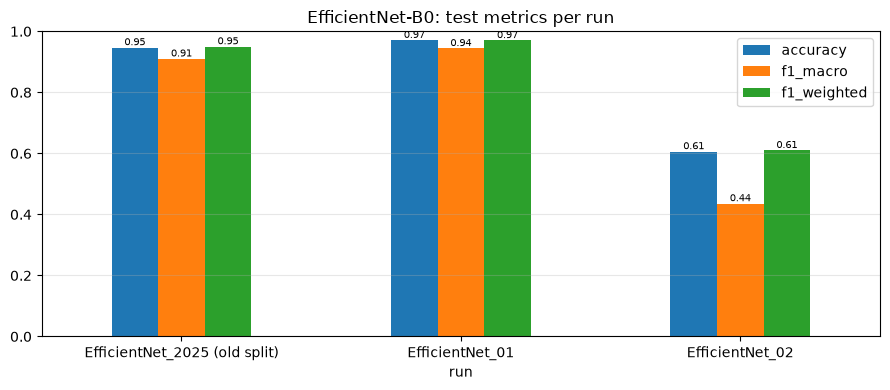

In [2]:
cols = ["accuracy", "f1_macro", "f1_weighted"]
ax = table.set_index("run")[cols].plot.bar(figsize=(9, 4), rot=0, ylim=(0, 1))
ax.set_title("EfficientNet-B0: test metrics per run"); ax.grid(axis="y", alpha=0.3)
for c in ax.containers: ax.bar_label(c, fmt="%.2f", fontsize=7)
plt.tight_layout(); plt.savefig(config.EVAL_DIR / "all_runs_comparison.png", dpi=150)

## Per-class F1: seen recordings (main) vs unseen recordings (grouped), the 34 shared species

34 shared species, mean F1: main 0.951 vs grouped 0.436


,F1 main (seen rec.),F1 grouped (unseen rec.),drop
GrayWhale,1.000,0.000,1.000
HarborPorpoise,1.000,0.000,1.000
ClymeneDolphin,0.969,0.000,0.969
WestIndianManatee,0.960,0.000,0.960
AtlanticSpottedDolphin,0.946,0.000,0.946
Narwhal,0.929,0.000,0.929
Walrus,0.974,0.075,0.899
Fraser_sDolphin,0.900,0.047,0.853
Short_Finned(Pacific)PilotWhale,0.956,0.180,0.776
StripedDolphin,0.956,0.208,0.748


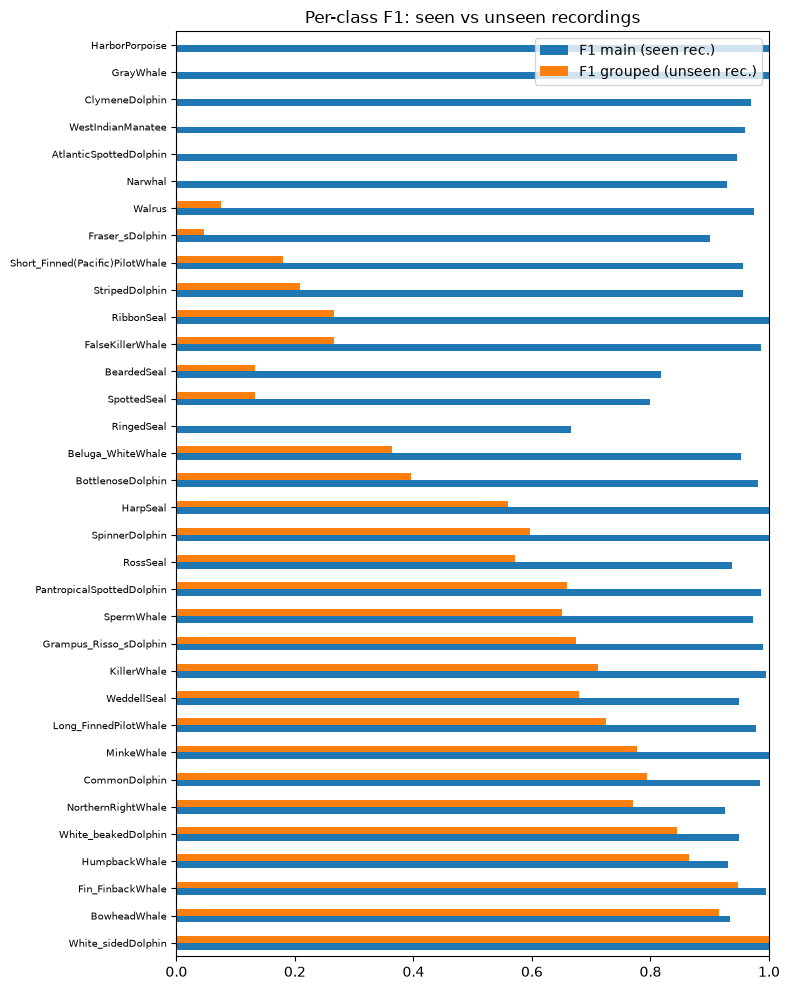

In [3]:
r1 = pd.read_csv(config.EVAL_DIR / "classification_report_EfficientNet_01.csv", index_col=0)
r2 = pd.read_csv(config.EVAL_DIR / "classification_report_EfficientNet_02.csv", index_col=0)
drop = ["accuracy", "macro avg", "weighted avg"]
cmp = pd.DataFrame({"F1 main (seen rec.)": r1.drop(index=drop)["f1-score"],
                    "F1 grouped (unseen rec.)": r2.drop(index=drop)["f1-score"]}).dropna()
cmp["drop"] = cmp.iloc[:, 0] - cmp.iloc[:, 1]
print(f"34 shared species, mean F1: main {cmp.iloc[:,0].mean():.3f} vs grouped {cmp.iloc[:,1].mean():.3f}")
ax = cmp.sort_values("drop").iloc[:, :2].plot.barh(figsize=(8, 10))
ax.set(xlim=(0, 1), title="Per-class F1: seen vs unseen recordings"); ax.tick_params(axis="y", labelsize=7)
plt.tight_layout(); plt.savefig(config.EVAL_DIR / "f1_seen_vs_unseen.png", dpi=150)
cmp.sort_values("drop", ascending=False).round(3)